# ARTI 403 — Image Processing
## Lab 2 — Digital Image Fundamentals

**College of Computer Science and Information Technology — Department of Computer Engineering**  
**Imam Abdulrahman Bin Faisal University — 2026 / 2027**

| | |
|---|---|
| **Session topic** | Digital Image Fundamentals |
| **Session No.** | 2 |
| **Duration** | 100 minutes |
| **Student name** | Abdulrahman Saleh Alaamri |
| **Student ID** | 2240002427 |

**Outcome #1:** Explain how digital images are represented and manipulated in a computer.

## 1. Image sampling and quantization

**Sampling** is how many pixels the image has. **Quantization** is how many gray levels each pixel can have.

### Step 1: Import the libraries

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

%matplotlib inline

### Step 2: Define the functions

In [2]:
def sample_image(image, factor):
    height, width = image.shape[:2]
    return cv2.resize(image, (width // factor, height // factor), interpolation=cv2.INTER_NEAREST)

In [3]:
def quantize_image(image, levels):
    step = 256 // levels
    return (np.floor(image / step) * step).astype(np.uint8)

In [4]:
def plot_images(original, sampled, quantized):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(original, cmap='gray')
    plt.title('Original Image')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(sampled, cmap='gray')
    plt.title('Sampled Image')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(quantized, cmap='gray')
    plt.title('Quantized Image')
    plt.axis('off')

    plt.show()

### Step 3: Load the image and set the parameters

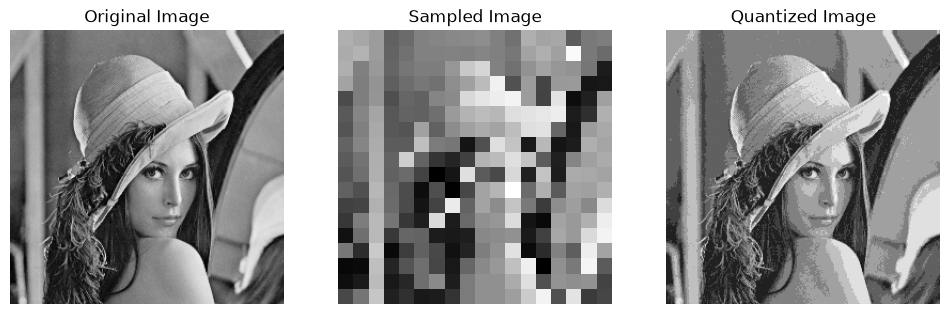

In [5]:
image_path = '../images/lena_gray_256.tif'
sampling_factor = 14
quantization_levels = 9

original_image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
if original_image is None:
    print("Unable to load image at", image_path)

sampled_image = sample_image(original_image, sampling_factor)
quantized_image = quantize_image(original_image, quantization_levels)

plot_images(original_image, sampled_image, quantized_image)

In [6]:
print("original  :", original_image.shape, len(np.unique(original_image)), "gray levels")
print("sampled   :", sampled_image.shape, len(np.unique(sampled_image)), "gray levels")
print("quantized :", quantized_image.shape, len(np.unique(quantized_image)), "gray levels")
print(np.unique(quantized_image))

original  : (256, 256) 210 gray levels
sampled   : (18, 18) 150 gray levels
quantized : (256, 256) 9 gray levels
[  0  28  56  84 112 140 168 196 224]


The sampled image looks as big as the others because matplotlib stretches it to the same box, but it has only 18 x 18 pixels. The quantized image has the same size but fewer gray levels.

`quantize_image()` uses the step `256 // levels`. With 9 levels the step is 28, so the values are 0, 28, 56, ... This gives exactly the number of levels only when `levels` is a power of 2.

## 2. Arithmetic operations

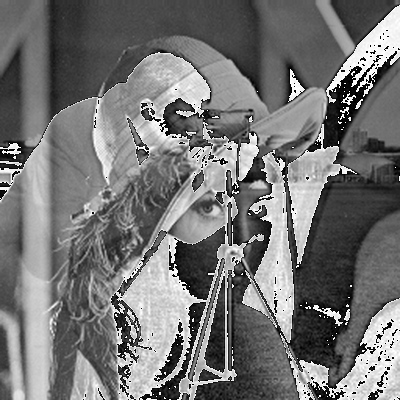

In [7]:
img1 = Image.open('../images/lena_gray_256.tif')
img2 = Image.open('../images/cameraman.tif')

resize = (400, 400)
img1 = img1.resize(resize, Image.Resampling.LANCZOS)
img2 = img2.resize(resize, Image.Resampling.LANCZOS)

im1arr = np.asarray(img1)
im2arr = np.asarray(img2)

addition = im1arr + im2arr
resultImage = Image.fromarray(addition)
display(resultImage)

The result looks broken because the arrays are `uint8`. When the sum is more than 255 it wraps around (300 becomes 44), so bright areas turn dark. Here are the correct ways to add two images:

pixels with a sum above 255: 85411 (53.4 %)


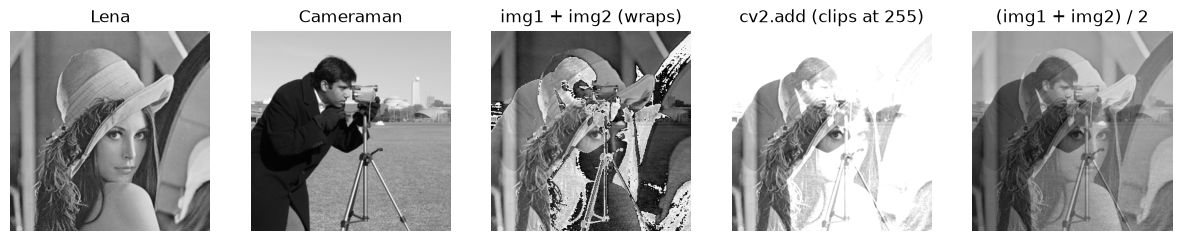

In [8]:
wrapped = im1arr + im2arr
saturated = cv2.add(im1arr, im2arr)
averaged = ((im1arr.astype(np.int16) + im2arr.astype(np.int16)) // 2).astype(np.uint8)

over = (im1arr.astype(np.int16) + im2arr.astype(np.int16)) > 255
print("pixels with a sum above 255:", over.sum(), f"({100 * over.mean():.1f} %)")

titles = ['Lena', 'Cameraman', 'img1 + img2 (wraps)', 'cv2.add (clips at 255)', '(img1 + img2) / 2']
imgs = [im1arr, im2arr, wrapped, saturated, averaged]

plt.figure(figsize=(15, 3.5))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(1, 5, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t)
    plt.axis('off')
plt.show()

## 3. Sets and logical operations

`A.png` and `B.png` are two binary images (0 and 255). A is a disk and B is a square. Logical operators on them work like set operators.

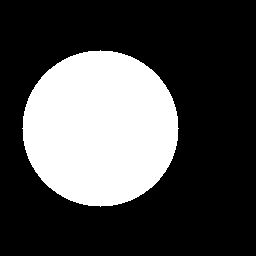

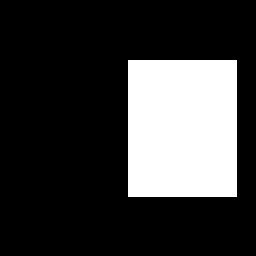

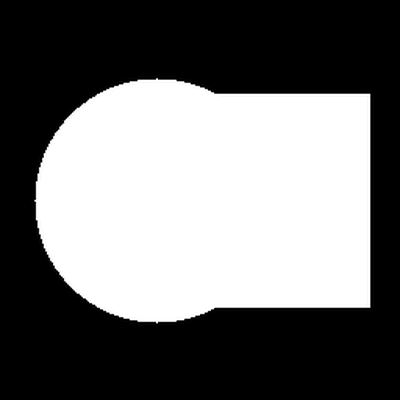

In [9]:
img3 = Image.open('../images/A.png')
display(img3)

img4 = Image.open('../images/B.png')
display(img4)

resize = (400, 400)
img3 = img3.resize(resize, Image.Resampling.LANCZOS)
img4 = img4.resize(resize, Image.Resampling.LANCZOS)

im3arr = np.asarray(img3)
im4arr = np.asarray(img4)

union = im4arr | im3arr
resultImage2 = Image.fromarray(union)
display(resultImage2)

Resizing with LANCZOS creates gray values on the edges, so I threshold the images again to keep them binary.

values of A: [  0 255] | values of B: [  0 255]


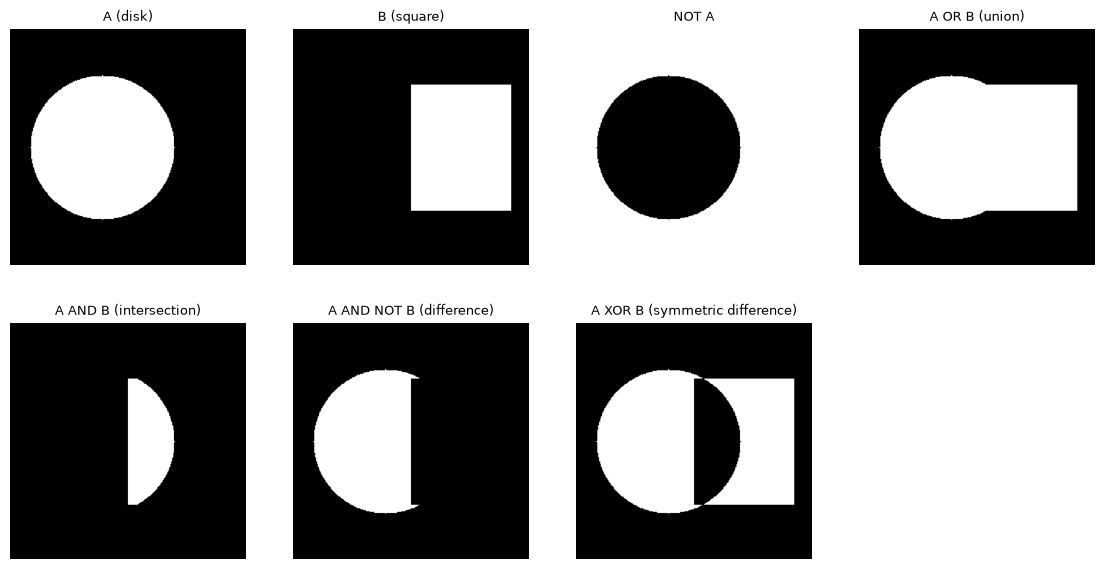

|A| = 46652, |B| = 36380, |A and B| = 12965, |A or B| = 70067
|A| + |B| - |A and B| = |A or B| : True


In [10]:
A = np.where(im3arr > 127, 255, 0).astype(np.uint8)
B = np.where(im4arr > 127, 255, 0).astype(np.uint8)
print("values of A:", np.unique(A), "| values of B:", np.unique(B))

not_A = cv2.bitwise_not(A)
union = cv2.bitwise_or(A, B)
inter = cv2.bitwise_and(A, B)
diff = cv2.bitwise_and(A, cv2.bitwise_not(B))
sym_diff = cv2.bitwise_xor(A, B)

titles = ['A (disk)', 'B (square)', 'NOT A', 'A OR B (union)', 'A AND B (intersection)',
          'A AND NOT B (difference)', 'A XOR B (symmetric difference)']
imgs = [A, B, not_A, union, inter, diff, sym_diff]

plt.figure(figsize=(14, 7))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(2, 4, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t, fontsize=9)
    plt.axis('off')
plt.show()

a, b = (A > 0).sum(), (B > 0).sum()
i_, u_ = (inter > 0).sum(), (union > 0).sum()
print(f"|A| = {a}, |B| = {b}, |A and B| = {i_}, |A or B| = {u_}")
print("|A| + |B| - |A and B| = |A or B| :", a + b - i_ == u_)

# Task 1: Change the sampling and quantization parameters

### 1.1 Effect of the sampling factor

Every image is drawn in the same box, so the pixels of the small images look like big blocks.

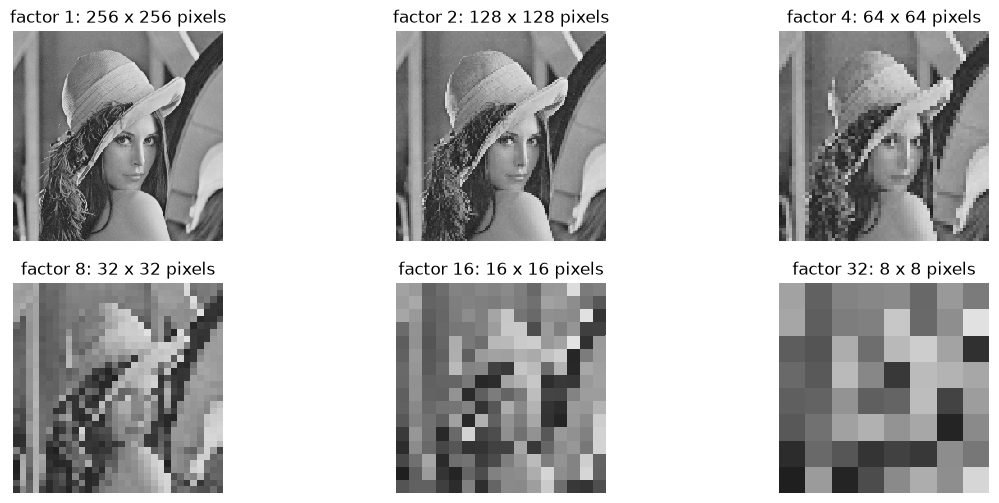

In [11]:
factors = [1, 2, 4, 8, 16, 32]

plt.figure(figsize=(14, 6))
for i, f in enumerate(factors, 1):
    sampled = sample_image(original_image, f)
    plt.subplot(2, 3, i)
    plt.imshow(sampled, cmap='gray', vmin=0, vmax=255, extent=[0, 256, 256, 0], interpolation='nearest')
    plt.title(f'factor {f}: {sampled.shape[1]} x {sampled.shape[0]} pixels')
    plt.axis('off')
plt.show()

**Observation:** A smaller number of pixels gives a lower spatial resolution. With factors 2 and 4 the image is still clear. From factor 8 the square pixels (blocks) are visible, and the edges look like stairs. With factor 32 (8 x 8 pixels) the face is not recognizable anymore.

### 1.2 Effect of the number of quantization levels

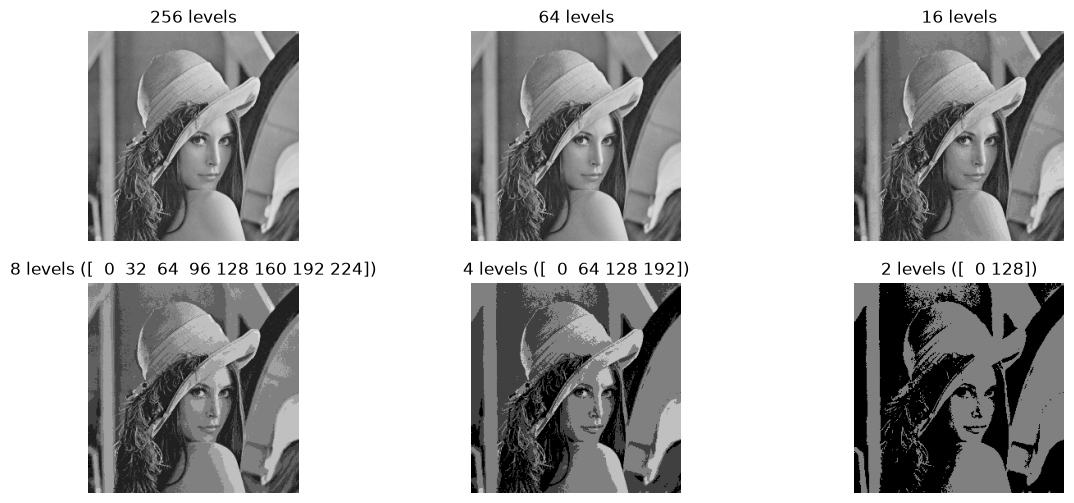

In [12]:
levels_list = [256, 64, 16, 8, 4, 2]

plt.figure(figsize=(14, 6))
for i, lv in enumerate(levels_list, 1):
    q = quantize_image(original_image, lv)
    plt.subplot(2, 3, i)
    plt.imshow(q, cmap='gray', vmin=0, vmax=255)
    plt.title(f'{lv} levels ({np.unique(q)})' if lv <= 8 else f'{lv} levels')
    plt.axis('off')
plt.show()

**Observation:** The image size does not change, only the number of shades. With 64 levels it looks the same as the original. With 16 levels bands start to appear, and with 8 levels or less they are very clear in the smooth areas (false contours). With 2 levels the function gives only the values 0 and 128, so the image is black and dark gray.

### 1.3 Sampling and quantization together

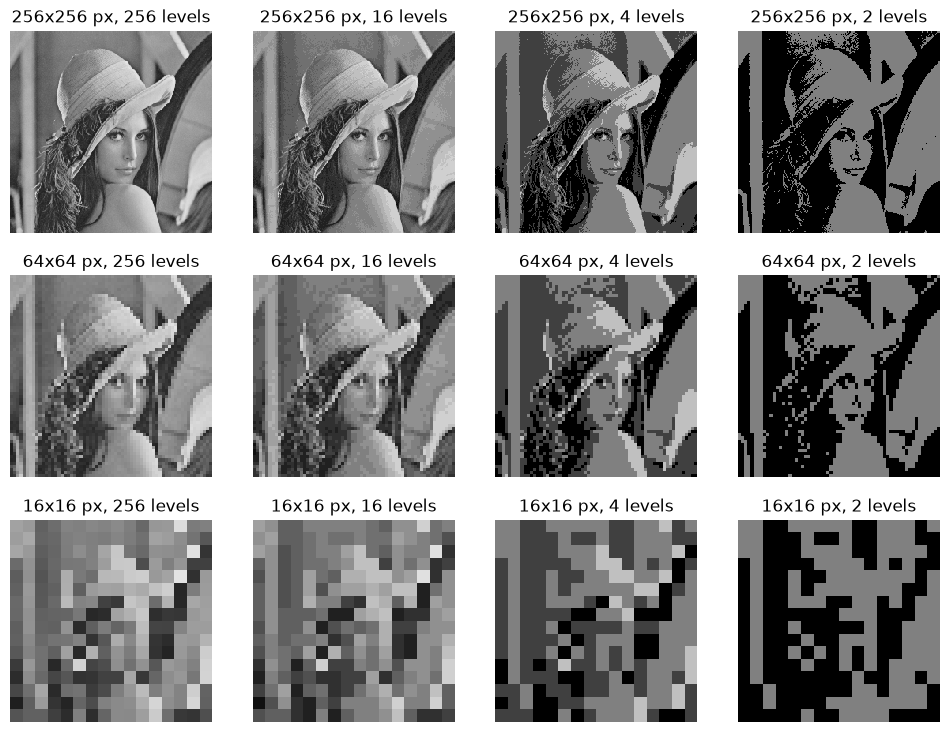

In [13]:
factors_g = [1, 4, 16]
levels_g = [256, 16, 4, 2]

fig, axes = plt.subplots(len(factors_g), len(levels_g), figsize=(12, 9))
for r, f in enumerate(factors_g):
    for c, lv in enumerate(levels_g):
        im = quantize_image(sample_image(original_image, f), lv)
        axes[r, c].imshow(im, cmap='gray', vmin=0, vmax=255, extent=[0, 256, 256, 0], interpolation='nearest')
        axes[r, c].set_title(f'{im.shape[1]}x{im.shape[0]} px, {lv} levels')
        axes[r, c].axis('off')
plt.show()

**Observation:** Sampling changes the details (blocks and jagged edges). Quantization changes the shades (bands). The storage is `N x N x log2(L) / 8` bytes, so I can lower the size with either one.

# Task 2: Arithmetic and set operations on two images

I read Lena (image A) and Cameraman (image B) and convert them to arrays.

A: (256, 256) uint8
B: (256, 256) uint8


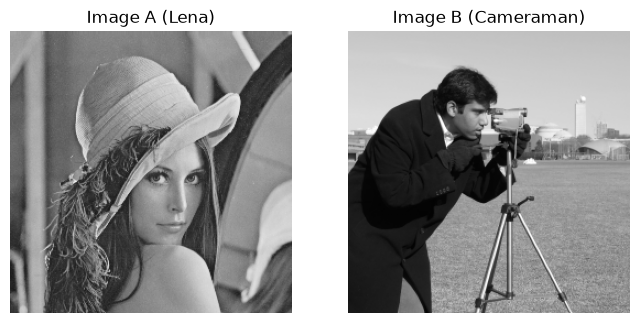

In [14]:
imgA = Image.open('../images/lena_gray_256.tif').convert('L')
imgB = Image.open('../images/cameraman.tif').convert('L')

size = (256, 256)
imgA = imgA.resize(size, Image.Resampling.LANCZOS)
imgB = imgB.resize(size, Image.Resampling.LANCZOS)

A = np.asarray(imgA)
B = np.asarray(imgB)

print("A:", A.shape, A.dtype)
print("B:", B.shape, B.dtype)

fig, ax = plt.subplots(1, 2, figsize=(8, 4))

ax[0].imshow(A, cmap='gray', vmin=0, vmax=255)
ax[0].set_title('Image A (Lena)')
ax[0].axis('off')

ax[1].imshow(B, cmap='gray', vmin=0, vmax=255)
ax[1].set_title('Image B (Cameraman)')
ax[1].axis('off')

plt.show()

## 2.1 Subtract two images

A subtraction can be negative and `uint8` cannot keep negative numbers, so I compare four ways.

pixels where A - B is negative: 36394 (55.5 %)
range of A - B: -221 to 213


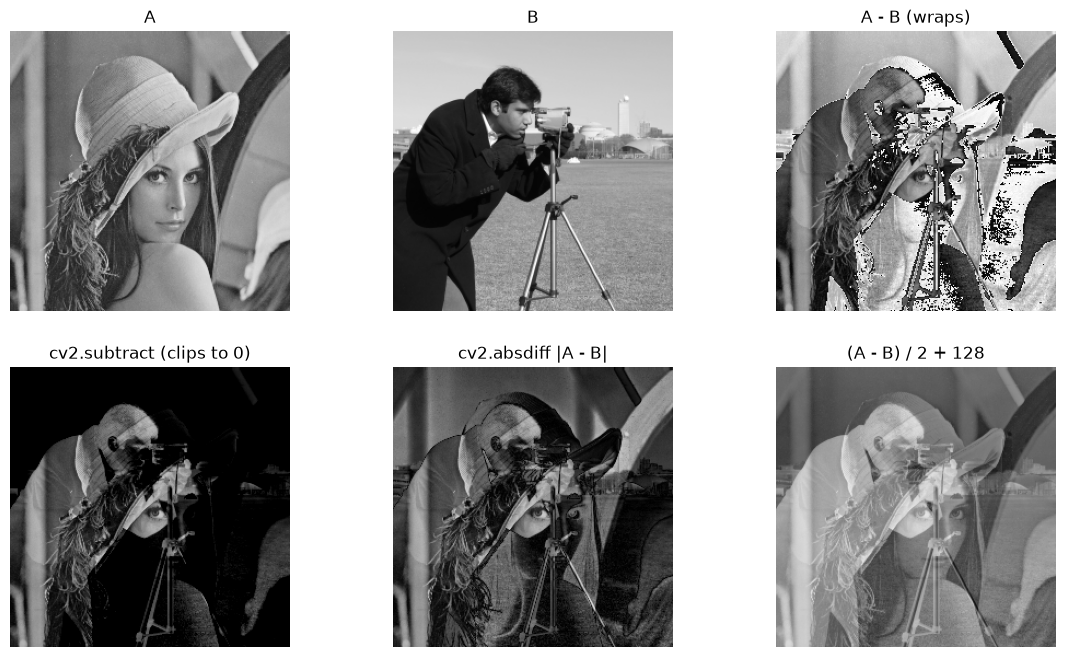

In [15]:
sub_wrap = A - B
sub_sat = cv2.subtract(A, B)
sub_abs = cv2.absdiff(A, B)
sub_shift = np.clip((A.astype(np.int16) - B.astype(np.int16)) // 2 + 128, 0, 255).astype(np.uint8)

true_diff = A.astype(np.int16) - B.astype(np.int16)
print("pixels where A - B is negative:", (true_diff < 0).sum(), f"({100 * (true_diff < 0).mean():.1f} %)")
print("range of A - B:", true_diff.min(), "to", true_diff.max())

titles = ['A', 'B', 'A - B (wraps)', 'cv2.subtract (clips to 0)', 'cv2.absdiff |A - B|', '(A - B) / 2 + 128']
imgs = [A, B, sub_wrap, sub_sat, sub_abs, sub_shift]

plt.figure(figsize=(14, 8))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(2, 3, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t)
    plt.axis('off')
plt.show()

**Observation:** The normal `A - B` has bright spots where B is brighter than A, because a negative value wraps to a big number. `cv2.subtract` makes those pixels black. `cv2.absdiff` keeps the size of the difference, so it is the best one to see where two images are different.

## 2.2 Add a constant value of 175

pixels above 255 after adding: 51325 (78.3 %)
mean of A       : 124.0
mean (wrapped)  : 98.5
mean (saturated): 249.6
clip equals cv2.add: True


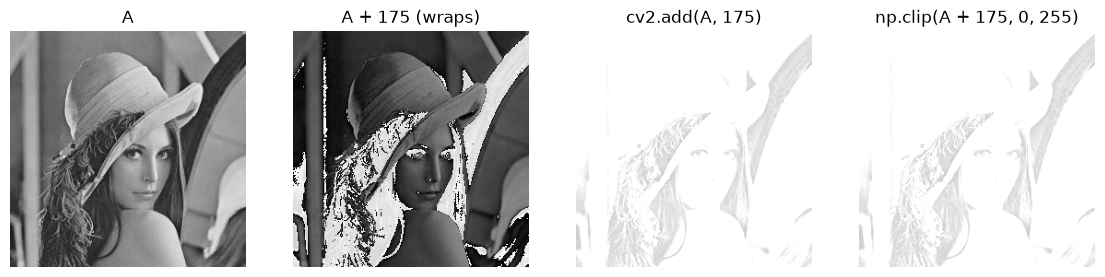

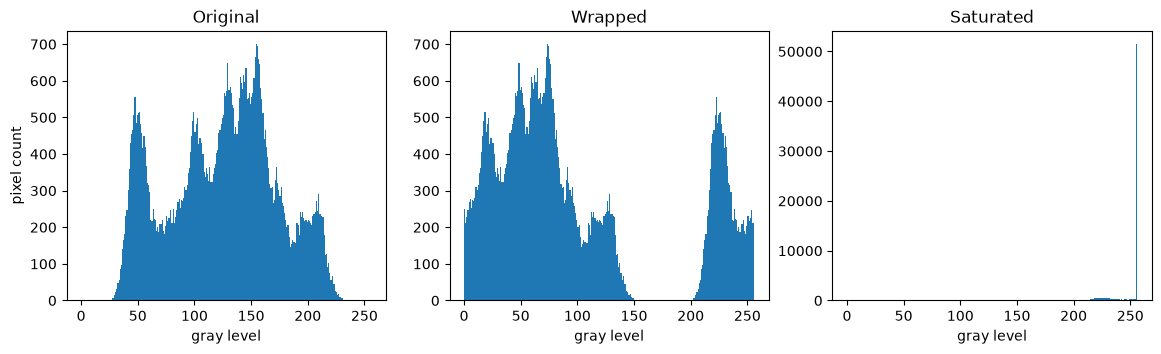

In [16]:
C = 175

add_wrap = A + np.uint8(C)
add_sat = cv2.add(A, np.full(A.shape, C, dtype=np.uint8))
add_clip = np.clip(A.astype(np.int16) + C, 0, 255).astype(np.uint8)

over = (A.astype(np.int16) + C) > 255
print("pixels above 255 after adding:", over.sum(), f"({100 * over.mean():.1f} %)")
print("mean of A       :", round(A.mean(), 1))
print("mean (wrapped)  :", round(add_wrap.mean(), 1))
print("mean (saturated):", round(add_sat.mean(), 1))
print("clip equals cv2.add:", np.array_equal(add_clip, add_sat))

titles = ['A', f'A + {C} (wraps)', f'cv2.add(A, {C})', f'np.clip(A + {C}, 0, 255)']
imgs = [A, add_wrap, add_sat, add_clip]

plt.figure(figsize=(14, 4))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(1, 4, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t)
    plt.axis('off')
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, im, t in zip(ax, [A, add_wrap, add_sat], ['Original', 'Wrapped', 'Saturated']):
    a.hist(im.ravel(), bins=256, range=(0, 256))
    a.set_title(t)
    a.set_xlabel('gray level')
ax[0].set_ylabel('pixel count')
plt.show()

**Observation:** The histogram of A is around gray level 120. After adding 175 most pixels go above 255. With wrapping they come back from 0, so bright areas become dark. With `cv2.add` they all stay at 255, and the image becomes almost white. Information is lost in both cases, but only the saturated version keeps brighter pixels brighter.

## 2.3 Set difference

For gray-scale images the set operations are done pixel by pixel:

| Operation | Formula |
|---|---|
| Complement | 255 - A |
| Union | max(A, B) |
| Intersection | min(A, B) |
| Difference A - B | min(A, 255 - B) |
| Symmetric difference | max(min(A, 255 - B), min(B, 255 - A)) |

A - B mean: 85.2
B - A mean: 90.3
A - B equals B - A: False


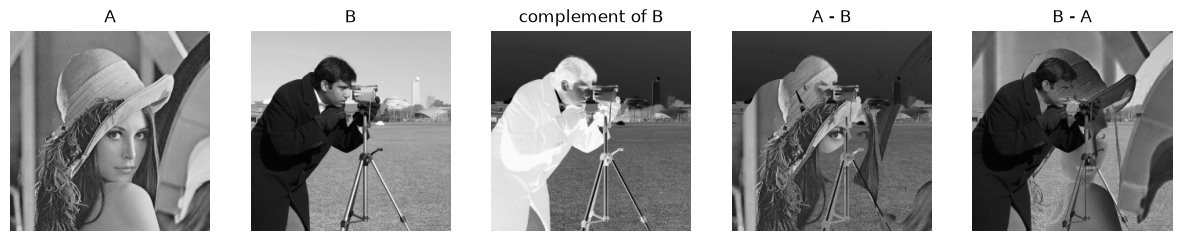

In [17]:
B_c = 255 - B
diff_AB = np.minimum(A, B_c)
diff_BA = np.minimum(B, 255 - A)

print("A - B mean:", round(diff_AB.mean(), 1))
print("B - A mean:", round(diff_BA.mean(), 1))
print("A - B equals B - A:", np.array_equal(diff_AB, diff_BA))

titles = ['A', 'B', 'complement of B', 'A - B', 'B - A']
imgs = [A, B, B_c, diff_AB, diff_BA]

plt.figure(figsize=(15, 3.5))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(1, 5, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t)
    plt.axis('off')
plt.show()

white pixels in A     : 33513
white pixels in B     : 42768
white pixels in A - B : 9473


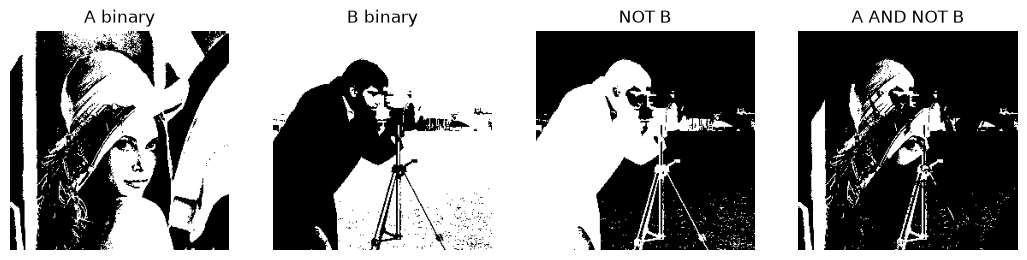

In [18]:
A_bin = np.where(A > 127, 255, 0).astype(np.uint8)
B_bin = np.where(B > 127, 255, 0).astype(np.uint8)
diff_bin = cv2.bitwise_and(A_bin, cv2.bitwise_not(B_bin))

print("white pixels in A     :", (A_bin > 0).sum())
print("white pixels in B     :", (B_bin > 0).sum())
print("white pixels in A - B :", (diff_bin > 0).sum())

titles = ['A binary', 'B binary', 'NOT B', 'A AND NOT B']
imgs = [A_bin, B_bin, cv2.bitwise_not(B_bin), diff_bin]

plt.figure(figsize=(13, 3.5))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(1, 4, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t)
    plt.axis('off')
plt.show()

**Observation:** A - B keeps a pixel of A only where B is dark. A - B is not the same as B - A, so the set difference is not commutative.

## 2.4 Symmetric difference

The symmetric difference is (A - B) union (B - A). On binary images it is the XOR.

white pixels in A xor B : 28201
|A - B| + |B - A|       : 28201


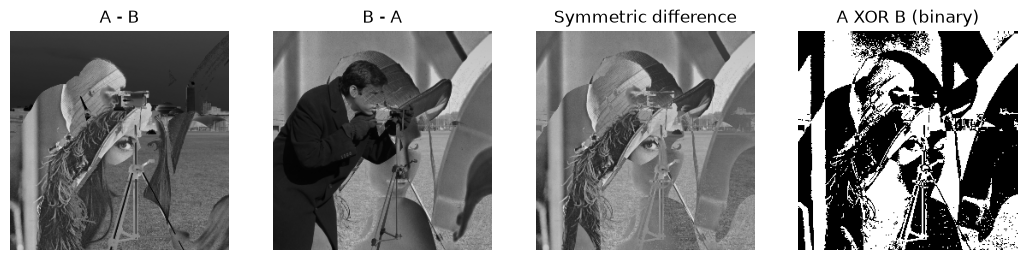

In [19]:
sym_gray = np.maximum(diff_AB, diff_BA)
sym_bin = cv2.bitwise_xor(A_bin, B_bin)

diff_bin_BA = cv2.bitwise_and(B_bin, cv2.bitwise_not(A_bin))
print("white pixels in A xor B :", (sym_bin > 0).sum())
print("|A - B| + |B - A|       :", (diff_bin > 0).sum() + (diff_bin_BA > 0).sum())

titles = ['A - B', 'B - A', 'Symmetric difference', 'A XOR B (binary)']
imgs = [diff_AB, diff_BA, sym_gray, sym_bin]

plt.figure(figsize=(13, 3.5))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(1, 4, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t)
    plt.axis('off')
plt.show()

**Observation:** The result is bright where one image is bright and the other is dark. It is black where both images agree. It is commutative, unlike the simple difference.

## 2.5 Intersection

The intersection is min(A, B). I also show the union max(A, B) to compare.

mean of A     : 124.0
mean of B     : 129.2
mean of min   : 92.9
mean of max   : 160.3


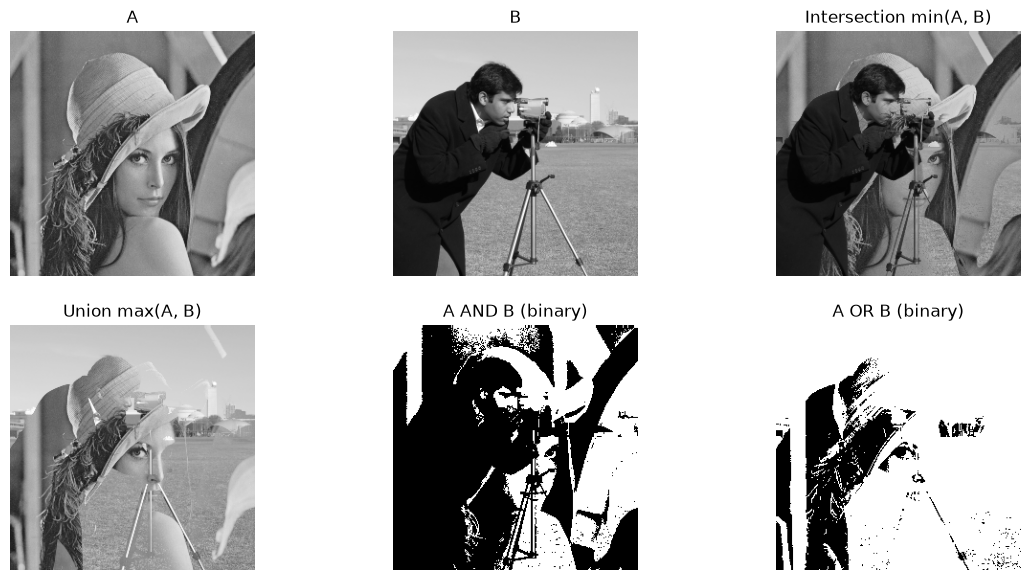

In [20]:
inter_gray = np.minimum(A, B)
union_gray = np.maximum(A, B)

print("mean of A     :", round(A.mean(), 1))
print("mean of B     :", round(B.mean(), 1))
print("mean of min   :", round(inter_gray.mean(), 1))
print("mean of max   :", round(union_gray.mean(), 1))

inter_bin = cv2.bitwise_and(A_bin, B_bin)
union_bin = cv2.bitwise_or(A_bin, B_bin)

titles = ['A', 'B', 'Intersection min(A, B)', 'Union max(A, B)', 'A AND B (binary)', 'A OR B (binary)']
imgs = [A, B, inter_gray, union_gray, inter_bin, union_bin]

plt.figure(figsize=(14, 7))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(2, 3, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t)
    plt.axis('off')
plt.show()

**Observation:** The intersection is always the darker of the two pixels, and the union is always the brighter one.

### Summary of Task 2

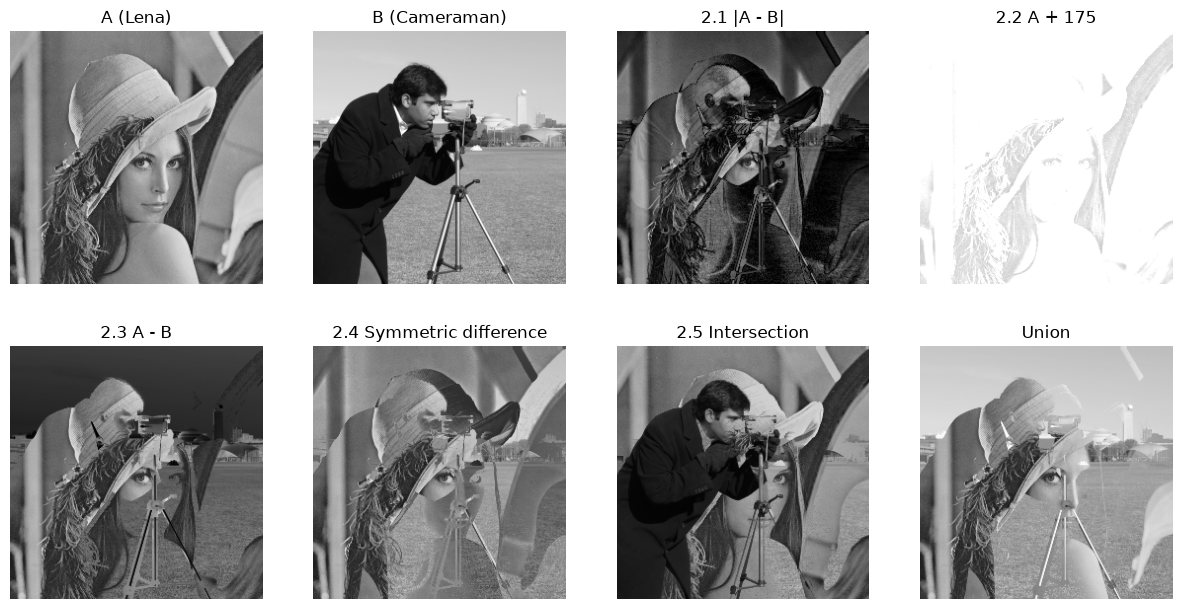

['task2_1_subtraction.png', 'task2_2_add_175.png', 'task2_3_set_difference.png', 'task2_4_symmetric_difference.png', 'task2_5_intersection.png', 'task2_union.png']


In [21]:
results = [
    ('A (Lena)', A, None),
    ('B (Cameraman)', B, None),
    ('2.1 |A - B|', sub_abs, 'task2_1_subtraction.png'),
    ('2.2 A + 175', add_sat, 'task2_2_add_175.png'),
    ('2.3 A - B', diff_AB, 'task2_3_set_difference.png'),
    ('2.4 Symmetric difference', sym_gray, 'task2_4_symmetric_difference.png'),
    ('2.5 Intersection', inter_gray, 'task2_5_intersection.png'),
    ('Union', union_gray, 'task2_union.png'),
]

plt.figure(figsize=(15, 7.5))
for i, (t, im, _) in enumerate(results, 1):
    plt.subplot(2, 4, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t)
    plt.axis('off')
plt.show()

os.makedirs('output', exist_ok=True)
for _, im, name in results:
    if name:
        cv2.imwrite('output/' + name, im)
print(sorted(os.listdir('output')))

## Conclusion

- **Sampling and quantization:** Fewer pixels give blocks and jagged edges. Fewer gray levels give bands (false contours). Lena is still fine at 128 x 128 pixels and about 32 gray levels.
- **Arithmetic:** `uint8` arrays wrap around when the result is outside 0 to 255. I can fix it by working in `int16` and using `np.clip`, or by using `cv2.add`, `cv2.subtract` and `cv2.absdiff`.
- **Sets:** For binary images, OR is the union, AND is the intersection, NOT is the complement and XOR is the symmetric difference. For gray images they become max, min and 255 - A.
- An image is a matrix of integers with a limited range, so every operation is just math on this matrix and I must respect the data type range.